IQR , ZSCORE
(IQR = Q3-Q1)

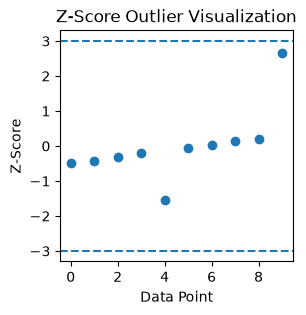

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import zscore

data = np.array([10, 12, 15, 18, -20, 22, 25, 28, 30, 100])

z_scores = zscore(data)
plt.figure(figsize=(3,3))

plt.scatter(range(len(data)), z_scores)

plt.axhline(3, linestyle="--")
plt.axhline(-3, linestyle="--")

plt.xlabel("Data Point")
plt.ylabel("Z-Score")
plt.title("Z-Score Outlier Visualization")

plt.show()   

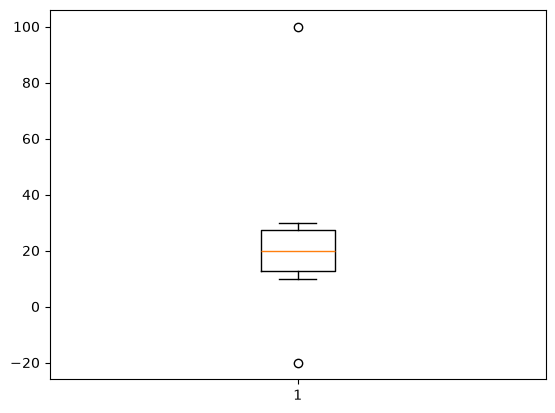

In [2]:
plt.boxplot(data)
plt.show()

In [3]:
import seaborn as sns 
import pandas as pd 

df=sns.load_dataset('tips')

In [4]:
df.head()   


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [5]:
Q1= df['total_bill'].quantile(0.25)
Q3=df['total_bill'].quantile(0.75)
IQR =Q3-Q1
print('IQR---',IQR)

IQR--- 10.779999999999998


In [6]:
lower = Q1-1.5*IQR

upper = Q3+1.5*IQR
print(lower,upper)

-2.8224999999999945 40.29749999999999


In [7]:
df.shape

(244, 7)

{'whiskers': [<matplotlib.lines.Line2D at 0x1e35c692a50>,
 'caps': [<matplotlib.lines.Line2D at 0x1e35c691fd0>,
 'boxes': [<matplotlib.lines.Line2D at 0x1e35c692270>],
 'medians': [<matplotlib.lines.Line2D at 0x1e35c692cf0>],
 'fliers': [<matplotlib.lines.Line2D at 0x1e35c692f90>],
 'means': []}

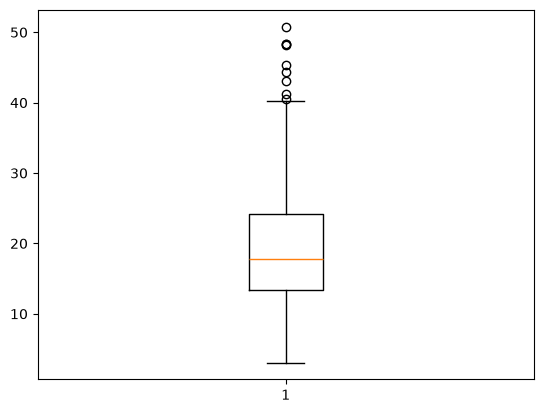

In [8]:
plt.boxplot(df['total_bill'])

In [9]:
Q1= df['total_bill'].quantile(0.25)
Q3=df['total_bill'].quantile(0.75)
IQR =Q3-Q1
lower = Q1-1.5*IQR

upper = Q3+1.5*IQR
df[(df['total_bill']<upper)& (df['total_bill']>lower)]

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


In [10]:
df.shape

(244, 7)

{'whiskers': [<matplotlib.lines.Line2D at 0x1e35c976660>,
 'caps': [<matplotlib.lines.Line2D at 0x1e35c976900>,
 'boxes': [<matplotlib.lines.Line2D at 0x1e35c976510>],
 'medians': [<matplotlib.lines.Line2D at 0x1e35c976ba0>],
 'fliers': [<matplotlib.lines.Line2D at 0x1e35c976cf0>],
 'means': []}

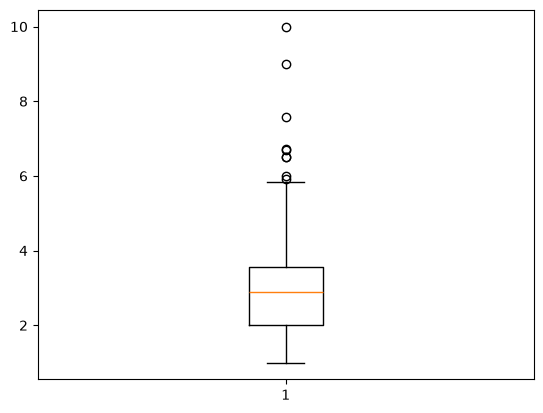

In [11]:
plt.boxplot(df['tip'])

In [12]:
Q1= df['tip'].quantile(0.25)
Q3=df['tip'].quantile(0.75)
IQR =Q3-Q1
print('IQR----',IQR)
lower = Q1-1.5*IQR
print('lower---',lower)
upper = Q3+1.5*IQR
print('upper----',upper)


IQR---- 1.5625
lower--- -0.34375
upper---- 5.90625


{'whiskers': [<matplotlib.lines.Line2D at 0x1e35cb317f0>,
 'caps': [<matplotlib.lines.Line2D at 0x1e35cb31a90>,
 'boxes': [<matplotlib.lines.Line2D at 0x1e35cb316a0>],
 'medians': [<matplotlib.lines.Line2D at 0x1e35cb31d30>],
 'fliers': [<matplotlib.lines.Line2D at 0x1e35cb31e80>],
 'means': []}

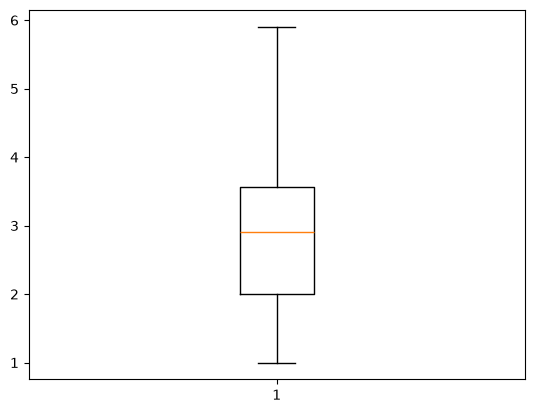

In [13]:
df['tip']=df['tip'].clip(upper=upper)
plt.boxplot(df['tip'])

coulmn transform

In [14]:
df

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01000,Female,No,Sun,Dinner,2
1,10.34,1.66000,Male,No,Sun,Dinner,3
2,21.01,3.50000,Male,No,Sun,Dinner,3
3,23.68,3.31000,Male,No,Sun,Dinner,2
4,24.59,3.61000,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.90625,Male,No,Sat,Dinner,3
240,27.18,2.00000,Female,Yes,Sat,Dinner,2
241,22.67,2.00000,Male,Yes,Sat,Dinner,2
242,17.82,1.75000,Male,No,Sat,Dinner,2


In [15]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder , MinMaxScaler
from sklearn.compose import ColumnTransformer

In [16]:
df.columns

Index(['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size'], dtype='str')

In [17]:
num_fea=['total_bill', 'tip','size']
ohe_fea=['sex', 'smoker']
label_fea=['day', 'time']

In [18]:
ColumnTransformer(transformers=[('num', StandardScaler(),num_fea),
('cat',OneHotEncoder(),ohe_fea),
('lab',LabelEncoder(),label_fea)])

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_n

In [19]:
num_fea=['total_bill']
ohe_fea=['sex', 'smoker']
min_max=['tip']

In [20]:
transformer = ColumnTransformer(transformers=[('num', StandardScaler(),num_fea),
('cat',OneHotEncoder(),ohe_fea),
('min_max',MinMaxScaler(),min_max)], remainder = 'passthrough')

In [21]:
transformer.fit_transform(df)

array([[-0.3147113050904943, 1.0, 0.0, ..., 'Sun', 'Dinner', 2],
       [-1.0632353132988692, 0.0, 1.0, ..., 'Sun', 'Dinner', 3],
       [0.13777989987156145, 0.0, 1.0, ..., 'Sun', 'Dinner', 3],
       ...,
       [0.3246295019205694, 0.0, 1.0, ..., 'Sat', 'Dinner', 2],
       [-0.2212865040659901, 0.0, 1.0, ..., 'Sat', 'Dinner', 2],
       [-0.11322890288102155, 1.0, 0.0, ..., 'Thur', 'Dinner', 2]],
      shape=(244, 9), dtype=object)

In [22]:
pd.DataFrame(transformer.fit_transform(df), columns=transformer.get_feature_names_out())

,num__total_bill,cat__sex_Female,cat__sex_Male,cat__smoker_No,cat__smoker_Yes,min_max__tip,remainder__day,remainder__time,remainder__size
0,-0.314711,1.0,0.0,1.0,0.0,0.002038,Sun,Dinner,2
1,-1.063235,0.0,1.0,1.0,0.0,0.134522,Sun,Dinner,3
2,0.13778,0.0,1.0,1.0,0.0,0.509554,Sun,Dinner,3
3,0.438315,0.0,1.0,1.0,0.0,0.470828,Sun,Dinner,2
4,0.540745,1.0,0.0,1.0,0.0,0.531975,Sun,Dinner,4
...,...,...,...,...,...,...,...,...,...
239,1.040511,0.0,1.0,1.0,0.0,1.0,Sat,Dinner,3
240,0.832275,1.0,0.0,0.0,1.0,0.203822,Sat,Dinner,2
241,0.32463,0.0,1.0,0.0,1.0,0.203822,Sat,Dinner,2
242,-0.221287,0.0,1.0,1.0,0.0,0.152866,Sat,Dinner,2


In [23]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression


model = Pipeline([("preprocesser", transformer),("logistic_model", LogisticRegression)])

LINEAR EQUATION


In [24]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

In [25]:
x = np.array([1,2,3,4,5,6,7,8]).reshape(-1,1)

y= np.array([12,22,32,42,52,62,72,80])

In [26]:
x.ndim

2

In [27]:
model= LinearRegression()
model.fit(x,y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[9.83]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.5
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[6.48]


In [28]:
M=model.coef_
C= model.intercept_

In [29]:
model.predict(x)

array([12.33333333, 22.16666667, 32.        , 41.83333333, 51.66666667,
       61.5       , 71.33333333, 81.16666667])

In [30]:
y

array([12, 22, 32, 42, 52, 62, 72, 80])

In [31]:
y_pred=model.predict(x)

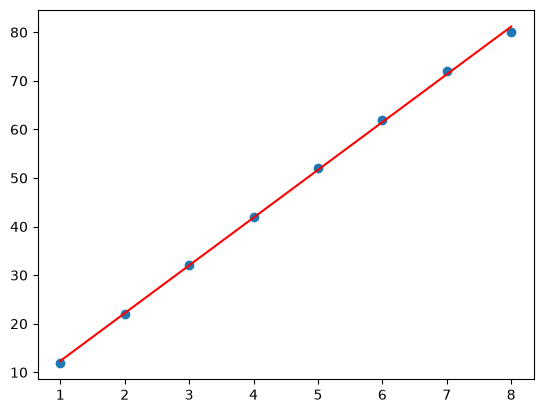

In [32]:
plt.scatter(x,y)
plt.plot(x,y_pred,color ='red')